# 2. Modélisation

**Entrée :** `data/batiments_cible.csv` (notebook d'analyse exploratoire).

### Import des modules 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
import shap

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv("data/batiments_cible.csv")
cible = "SiteEnergyUse(kBtu)"
print(df.shape)

(1479, 19)


### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

Le nettoyage, le feature engineering, la corrélation et les transformations sont faits dans le notebook 1. Ici, il reste à séparer X et y, puis à encoder.

#### Séparation X / y

In [3]:
# X = les infos du bâtiment, sans l'autre cible (CO2) ni l'ENERGY STAR Score (testé à la fin)
X = df.drop(columns=[cible, "TotalGHGEmissions", "ENERGYSTARScore"])
# y = la conso en log10 (6 = 1 million de kBtu), voir la distribution dans le notebook 1
y = np.log10(df[cible])

# 80 % pour entraîner, 20 % gardés de côté pour le test final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train :", X_train.shape, " test :", X_test.shape)

train : (1183, 16)  test : (296, 16)


#### Encodage et mise à l'échelle

Les colonnes texte passent dans un `OneHotEncoder` (une colonne 0/1 par catégorie). Avec `handle_unknown="ignore"`, on évite une erreur si une catégorie rare n'apparaît que dans le test. `sparse_output=False` donne un tableau normal plutôt qu'une matrice creuse, ce qui est plus simple pour SHAP à la fin.

Je n'ai pas pris le `LabelEncoder` parce qu'il transforme les catégories en 1, 2, 3… et le modèle penserait qu'il y a un ordre entre les quartiers ou les usages.

Les colonnes numériques passent dans un `StandardScaler` pour être à la même échelle, ce qui est nécessaire pour le SVR et la régression linéaire.

Je mets ce préprocesseur dans un `Pipeline` avec chaque modèle. Comme ça, l'encodage et le scaling sont calculés seulement sur la partie entraînement à chaque tour de la validation croisée. Sinon, une partie de l'info du test passerait dans l'entraînement.

In [4]:
colonnes_texte = X.select_dtypes(exclude="number").columns.tolist()
colonnes_nombres = X.select_dtypes("number").columns.tolist()
print("texte :", colonnes_texte)
print("nombres :", colonnes_nombres)

preprocesseur = ColumnTransformer([
    ("texte", OneHotEncoder(handle_unknown="ignore", sparse_output=False), colonnes_texte),
    ("nombres", StandardScaler(), colonnes_nombres),
])

# vérification : combien de colonnes après encodage ?
print(preprocesseur.fit_transform(X_train).shape)

texte : ['PrimaryPropertyType', 'Neighborhood', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'Periode']
nombres : ['NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'UtiliseGaz', 'UtiliseVapeur', 'PartParking', 'NbUsages']
(1183, 180)


### Optimisation des modèles

Je règle chaque modèle avec un GridSearch avant de les comparer. Sinon, je comparerais des modèles réglés par défaut, ce qui n'est pas juste pour ceux qui ont besoin d'être réglés (le RandomForest surtout).

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

Les hyperparamètres testés :

- **Dummy** et **régression linéaire** : rien à régler, le GridSearch fait juste une validation croisée.
- **SVR** : `C` (plus il est grand, plus le modèle colle aux données d'entraînement), `gamma` (plus il est grand, plus la courbe peut être tordue) et `epsilon` (l'erreur qu'on tolère sans pénalité).
- **RandomForest** : `n_estimators` (le nombre d'arbres), `max_depth` (la profondeur maximale des arbres) et `min_samples_leaf` (le nombre minimum de bâtiments au bout d'une branche). Les deux derniers servent à limiter le sur-apprentissage.

Chaque combinaison est testée en validation croisée à 5 plis, sur le jeu d'entraînement seulement.

In [5]:
# pour chaque modèle : (le modèle, sa grille). "modele__" = le paramètre appartient à l'étape "modele" du pipeline
modeles = {
    "Dummy": (DummyRegressor(), {}),
    "Régression linéaire": (LinearRegression(), {}),
    "SVR": (SVR(), {
        "modele__C": [1, 10, 100],
        "modele__gamma": ["scale", 0.01, 0.001],
        "modele__epsilon": [0.1, 0.2],
    }),
    "RandomForest": (RandomForestRegressor(random_state=42), {
        "modele__n_estimators": [100, 300],
        "modele__max_depth": [10, 20, None],
        "modele__min_samples_leaf": [1, 3, 5],
    }),
}

# sklearn renvoie les erreurs en négatif (plus c'est grand, mieux c'est), on remettra le signe
metriques = {"R2": "r2", "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}

grids = {}
for nom, (modele, grille) in modeles.items():
    pipe = Pipeline([("preprocesseur", preprocesseur), ("modele", modele)])
    # refit="R2" : la meilleure combinaison est choisie sur le R2
    grid = GridSearchCV(pipe, grille, cv=5, scoring=metriques, refit="R2", return_train_score=True, n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[nom] = grid
    print(nom, ":", grid.best_params_)

Dummy : {}


Régression linéaire : {}


SVR : {'modele__C': 100, 'modele__epsilon': 0.1, 'modele__gamma': 0.001}


RandomForest : {'modele__max_depth': 20, 'modele__min_samples_leaf': 1, 'modele__n_estimators': 300}


Pour le SVR, la meilleure combinaison est C = 100, gamma = 0,001 et epsilon = 0,1. Pour le RandomForest, c'est 300 arbres avec une profondeur maximale de 20 et au moins 1 bâtiment par feuille, donc des arbres encore très profonds.

### Comparaison des modèles optimisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [6]:
# pour chaque modèle, les scores de sa meilleure combinaison (moyenne des 5 plis)
resultats = []
for nom, grid in grids.items():
    res = grid.cv_results_
    i = grid.best_index_
    resultats.append({
        "modèle": nom,
        "R2 train": res["mean_train_R2"][i],
        "R2 validation": res["mean_test_R2"][i],
        "MAE train": -res["mean_train_MAE"][i],
        "MAE validation": -res["mean_test_MAE"][i],
        "RMSE train": -res["mean_train_RMSE"][i],
        "RMSE validation": -res["mean_test_RMSE"][i],
        "temps (s)": res["mean_fit_time"][i],
    })

pd.DataFrame(resultats).round(3)

,modèle,R2 train,R2 validation,MAE train,MAE validation,RMSE train,RMSE validation,temps (s)
0,Dummy,0.000,-0.002,0.450,0.450,0.562,0.562,0.033
1,Régression linéaire,0.821,0.742,0.179,0.216,0.238,0.284,0.038
2,SVR,0.824,0.758,0.174,0.206,0.236,0.275,0.103
3,RandomForest,0.958,0.727,0.087,0.220,0.115,0.292,2.208


Les 3 modèles font beaucoup mieux que le Dummy (R² proche de 0), donc ils apprennent bien quelque chose.

Le SVR est le meilleur en validation (R² = 0,76 et MAE = 0,21). Une MAE de 0,21 en log10 veut dire qu'on se trompe en général d'un facteur 1,6 environ sur la consommation. Son écart entre train et validation reste raisonnable (0,82 contre 0,76).

Même réglé, le RandomForest reste à 0,73 en validation et sur-apprend toujours (0,96 en train) : le GridSearch garde des arbres profonds, parce que les arbres plus limités ne font pas mieux en validation. La régression linéaire est juste derrière le SVR avec 0,74.

Je garde donc le SVR.

In [7]:
meilleur = grids["SVR"]

#### Évaluation finale sur le jeu de test

Je n'ai pas touché au jeu de test jusqu'ici, c'est lui qui donne la vraie performance du modèle.

In [8]:
y_pred = meilleur.predict(X_test)

print("R2 test :", round(r2_score(y_test, y_pred), 3))
print("MAE test :", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

R2 test : 0.737
MAE test : 0.222
RMSE test : 0.298


R² = 0,74 sur le test, proche de la validation (0,76), donc le modèle marche aussi sur des bâtiments qu'il n'a jamais vus. Il explique environ 74 % des variations de consommation (en log) avec seulement des informations connues sans compteur.

#### Variables les plus importantes : SHAP

SHAP calcule, pour chaque bâtiment, de combien chaque variable fait monter ou descendre la prédiction par rapport à la moyenne. En plus de l'importance des variables, on voit donc aussi dans quel sens elles jouent.

SHAP travaille sur les colonnes après encodage (180 colonnes), donc on lit par exemple « usage principal = Hospital » et pas seulement « usage principal ». Avec un SVR, le calcul est lent, donc je le fais sur 100 bâtiments du jeu de test.

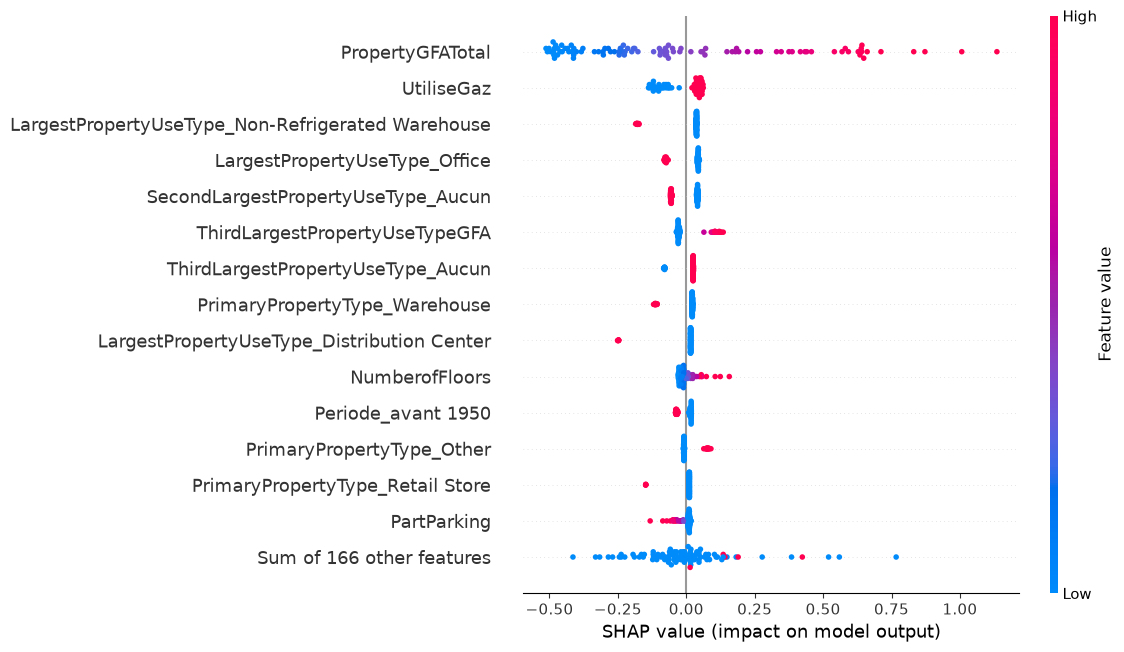

In [9]:
# je sépare le préprocesseur et le SVR du meilleur pipeline
preprocesseur_final = meilleur.best_estimator_.named_steps["preprocesseur"]
svr_final = meilleur.best_estimator_.named_steps["modele"]

# noms des colonnes après encodage, sans le préfixe ("texte__Periode_1950-1979" -> "Periode_1950-1979")
noms = [nom.split("__")[1] for nom in preprocesseur_final.get_feature_names_out()]
X_train_t = pd.DataFrame(preprocesseur_final.transform(X_train), columns=noms)
X_test_t = pd.DataFrame(preprocesseur_final.transform(X_test), columns=noms, index=X_test.index)

# 100 bâtiments du train servent de référence, 100 bâtiments du test sont expliqués
# .values : le SVR a été entraîné sans noms de colonnes, on les redonne à SHAP avec feature_names
explainer = shap.Explainer(svr_final.predict, shap.sample(X_train_t, 100, random_state=42).values, feature_names=noms)
shap_values = explainer(X_test_t.sample(100, random_state=42).values, silent=True)

shap.plots.beeswarm(shap_values, max_display=15)

In [10]:
# importance moyenne (valeur absolue des SHAP) des 10 colonnes les plus importantes
importances = pd.Series(np.abs(shap_values.values).mean(axis=0), index=noms)
importances.sort_values(ascending=False).head(10).round(3)

PropertyGFATotal                                     0.346
UtiliseGaz                                           0.062
LargestPropertyUseType_Non-Refrigerated Warehouse    0.055
LargestPropertyUseType_Office                        0.054
SecondLargestPropertyUseType_Aucun                   0.047
ThirdLargestPropertyUseTypeGFA                       0.043
ThirdLargestPropertyUseType_Aucun                    0.035
PrimaryPropertyType_Warehouse                        0.034
LargestPropertyUseType_Distribution Center           0.032
NumberofFloors                                       0.023
dtype: float64

Chaque point est un bâtiment. Sa position dit de combien la variable fait monter (à droite) ou descendre (à gauche) la prédiction, et sa couleur dit si la valeur de la variable est grande (rouge) ou petite (bleu).

La surface totale est de loin la plus importante : les grands bâtiments (en rouge) sont poussés jusqu'à +1,1 en log, soit plus de 10 fois plus, et les petits (en bleu) jusqu'à -0,5. Ensuite viennent l'usage du gaz (un peu plus de consommation quand le bâtiment est raccordé) et les usages : un entrepôt ou un centre de distribution fait baisser la prédiction de 0,2 environ, un bureau ou un bâtiment sans 2e usage un peu moins. Le nombre d'étages et la période jouent peu.

En résumé, pour prédire la consommation d'un bâtiment non résidentiel à Seattle, il faut surtout connaître sa surface, puis son usage.

#### Exemple sur un bâtiment

Je prends le plus grand hôpital du jeu de test pour voir comment le modèle arrive à sa prédiction.

conso réelle (log10) : 8.46
conso prédite (log10) : 8.61


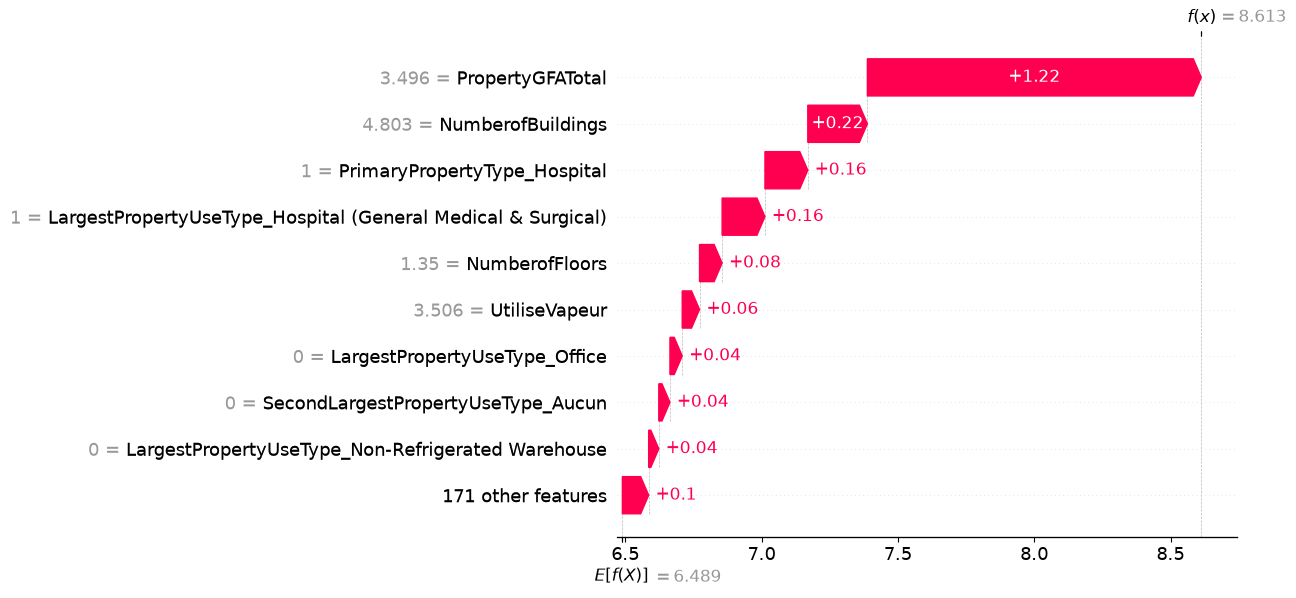

In [11]:
hopitaux = X_test[X_test["PrimaryPropertyType"] == "Hospital"]
hopital = hopitaux["PropertyGFATotal"].idxmax()

shap_hopital = explainer(X_test_t.loc[[hopital]].values, silent=True)
print("conso réelle (log10) :", round(y_test[hopital], 2))
print("conso prédite (log10) :", round(meilleur.predict(X_test.loc[[hopital]])[0], 2))

shap.plots.waterfall(shap_hopital[0], max_display=10)

Le graphique part de la prédiction moyenne du modèle (6,49 en log, environ 3 millions de kBtu) et ajoute l'effet de chaque variable. Les valeurs à gauche des noms sont celles après mise à l'échelle (par exemple 3,5 pour la surface veut dire très au-dessus de la moyenne).

Pour cet hôpital, la surface ajoute à elle seule +1,23. Le fait qu'il ait plusieurs bâtiments ajoute +0,22, et le fait que ce soit un hôpital environ +0,32 (type de bâtiment et usage principal). Le modèle prédit 8,61 alors que la vraie valeur est 8,46 : il surestime d'un facteur 1,4 environ, ce qui reste dans l'ordre de grandeur de l'erreur moyenne.

#### Test : le modèle avec `ENERGYSTARScore`

J'avais mis ce score de côté en créant X. Je le remets ici pour voir ce qu'il apporte, avec le même SVR. Pour les 35 % de cases vides, je mets la médiane calculée sur le jeu d'entraînement.

In [12]:
score_es = df["ENERGYSTARScore"]

X_train_es = X_train.copy()
X_test_es = X_test.copy()
X_train_es["ENERGYSTARScore"] = score_es[X_train.index]
X_test_es["ENERGYSTARScore"] = score_es[X_test.index]

# médiane calculée sur le train seulement
mediane = X_train_es["ENERGYSTARScore"].median()
X_train_es["ENERGYSTARScore"] = X_train_es["ENERGYSTARScore"].fillna(mediane)
X_test_es["ENERGYSTARScore"] = X_test_es["ENERGYSTARScore"].fillna(mediane)

In [13]:
preprocesseur_es = ColumnTransformer([
    ("texte", OneHotEncoder(handle_unknown="ignore"), colonnes_texte),
    ("nombres", StandardScaler(), colonnes_nombres + ["ENERGYSTARScore"]),
])

# même SVR que le GridSearch
pipe_es = Pipeline([("preprocesseur", preprocesseur_es), ("modele", SVR())])
pipe_es.set_params(**meilleur.best_params_)

scores_es = cross_validate(pipe_es, X_train_es, y_train, cv=5, scoring="r2")
pipe_es.fit(X_train_es, y_train)

print("sans le score : R2 validation", round(meilleur.best_score_, 3), "| R2 test", round(r2_score(y_test, y_pred), 3))
print("avec le score : R2 validation", round(scores_es["test_score"].mean(), 3), "| R2 test", round(r2_score(y_test, pipe_es.predict(X_test_es)), 3))

sans le score : R2 validation 0.758 | R2 test 0.737
avec le score : R2 validation 0.809 | R2 test 0.789


Avec le score, le modèle est meilleur (R² de validation de 0,76 à 0,81, et de 0,74 à 0,79 sur le test).

Je ne le garde quand même pas dans le modèle final. Le score ENERGY STAR est calculé à partir de la consommation mesurée, donc c'est en partie la réponse (fuite de données). Et pour un bâtiment qui n'a jamais été mesuré, la ville n'a pas ce score, donc le modèle ne servirait à rien. En plus, il manque déjà pour 35 % des bâtiments.

Le modèle final reste donc le SVR sans le score, avec un R² de 0,74 sur le test.